# ML-06 — Signal Audit: Do the Flags Hold?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/M-Abdullah-Nazeer/Flyrank-Ml-Pipeline/blob/main/work/notebooks/w04_signal_audit.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

In [2]:
!pip -q install duckdb
import duckdb, os
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from google.colab import userdata

con = duckdb.connect()
con.execute(f"CREATE SECRET (TYPE huggingface, TOKEN '{userdata.get('HF_TOKEN')}')")
rel = "hf://datasets/FlyRank/internship-warehouse"
con.sql(f"""CREATE OR REPLACE TABLE d AS
SELECT * FROM read_parquet('{rel}/fact_content_daily_performance/month=2026-03/*.parquet')""")

page = con.sql("""
WITH past AS (
  SELECT client_hash_id, content_hash_id,
         SUM(gsc_impressions) AS impressions, SUM(gsc_clicks) AS clicks,
         SUM(gsc_avg_position * gsc_impressions) / NULLIF(SUM(gsc_impressions), 0) AS position,
         SUM(CASE WHEN report_date BETWEEN DATE '2026-03-08' AND DATE '2026-03-15' THEN gsc_impressions END) AS impr_late,
         SUM(CASE WHEN report_date BETWEEN DATE '2026-03-01' AND DATE '2026-03-07' THEN gsc_impressions END) AS impr_early
  FROM d
  WHERE gsc_data_available IS TRUE AND report_date <= DATE '2026-03-15' AND gsc_impressions > 0
  GROUP BY 1, 2),
fut AS (
  SELECT client_hash_id, content_hash_id, SUM(gsc_impressions) AS f_impr, SUM(gsc_clicks) AS f_clicks
  FROM d WHERE gsc_data_available IS TRUE AND report_date > DATE '2026-03-15'
  GROUP BY 1, 2)
SELECT p.*, f.f_impr, f.f_clicks FROM past p LEFT JOIN fut f USING (client_hash_id, content_hash_id)
""").df()

page["ctr"] = page["clicks"] / page["impressions"]
page["trend_ratio"] = page["impr_late"] / page["impr_early"]
page["pos_bucket"] = pd.cut(page["position"], [0, 3, 6, 10, 20, 1000], labels=["1-3", "4-6", "7-10", "11-20", "21+"])
expected = (page.groupby("pos_bucket", observed=True)["clicks"].sum()
            / page.groupby("pos_bucket", observed=True)["impressions"].sum()).to_dict()
page["expected_ctr"] = page["pos_bucket"].map(expected).astype(float)

aud = page[(page["impressions"] >= 100) & (page["position"] <= 20) & page["f_impr"].notna()].copy()
aud["ctr_gap_ratio"] = aud["ctr"] / aud["expected_ctr"]
aud["f_expected_clicks"] = aud["f_impr"] * aud["expected_ctr"]
print(page.shape, aud.shape)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

(151981, 13) (62207, 15)


## 1. Distributions

*Look before deciding: distributions of your key fields. Note the heavy tails.*

Impressions and clicks are heavily right-skewed: the median page has far fewer impressions than the average, and a few pages account for most of the volume (see the 90th and 99th percentiles). Most pages have a CTR near zero, with a long tail up to 100% on tiny samples. Because of this, I use pooled CTR per bucket (clicks ÷ impressions) instead of averaging page CTRs, and I only audit pages with at least 100 impressions.

,count,mean,std,min,50%,90%,99%,max
impressions,151981.0,838.9793,2676.2418,1.0,107.000,2023.0000,11340.6000,161575.0
clicks,151981.0,2.5320,13.2401,0.0,0.000,5.0000,39.0000,2395.0
position,151981.0,15.6408,17.9015,0.0,8.052,40.3796,80.6667,310.0
ctr,151981.0,0.0045,0.0377,0.0,0.000,0.0066,0.0556,1.0


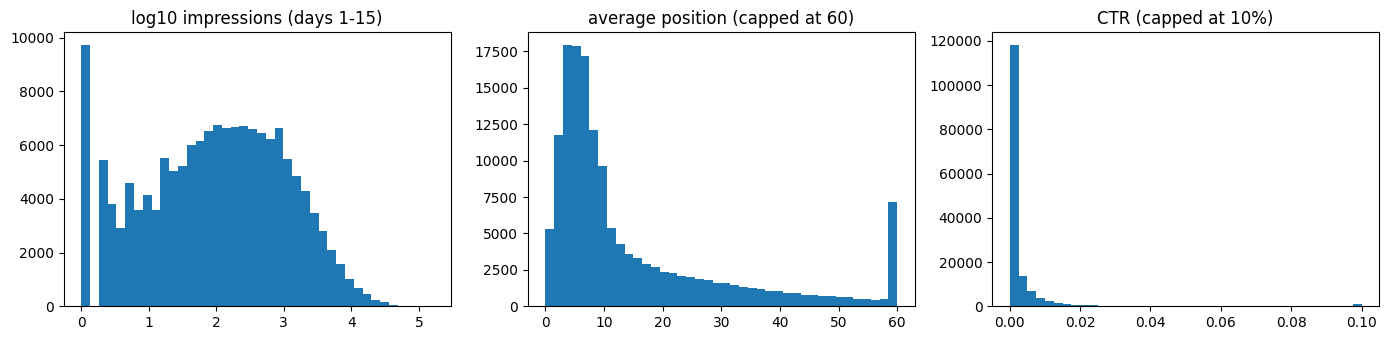

In [3]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
display(page[["impressions", "clicks", "position", "ctr"]].describe(percentiles=[.5, .9, .99]).T.round(4))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].hist(np.log10(page["impressions"]), bins=40); ax[0].set_title("log10 impressions (days 1-15)")
ax[1].hist(page["position"].clip(upper=60), bins=40); ax[1].set_title("average position (capped at 60)")
ax[2].hist(page["ctr"].clip(upper=0.1), bins=40); ax[2].set_title("CTR (capped at 10%)")
plt.tight_layout(); plt.show()

## 2. Signal test #1 / #2 / #3 (verdict each)

*Three safe signals, each with a mini-test and a verdict: CONFIRMED / OPPOSITE / MIXED / FALSE.*

**Signal 1, volume (hypothesis: higher volume → future clicks closer to or above expected): VERDICT FALSE.** Future actual vs expected clicks by volume bucket: 100-300 impressions 0.822 (n = 18,677), 300-1k 0.934 (n = 22,120), 1k-5k 0.865 (n = 17,516), 5k+ 0.870 (n = 3,894). The numbers do not rise with volume (the best bucket is 300-1k) and all stay below 1.0, so volume alone does not tell us which pages keep under-capturing. It is still useful for sizing the missed clicks, but not as a ranking signal on its own.

**Signal 2, trend (hypothesis: growing pages keep over-performing): VERDICT MIXED.** Shrinking pages did clearly worst (0.733, n = 9,677), but growing pages (0.865, n = 18,510) did no better than flat pages (0.893, n = 32,132). So declining impressions are a warning sign, while growth is not a reason to expect better CTR.

**Signal 3, position (hypothesis: worse position → lower future actual vs expected): VERDICT MIXED.** Top-3 pages 0.826 (n = 10,137), 4-6 0.866 (n = 21,516), 7-10 0.978 (n = 17,245), 11-20 0.876 (n = 13,309). It is not monotonic: the top-3 bucket is the lowest, and 7-10 is the best, so position does not follow the simple "worse position, lower CTR vs expected" story here.

In [4]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
def audit(col, bins, labels, hypothesis):
    a = aud.dropna(subset=[col]).copy()
    a["bucket"] = pd.cut(a[col], bins, labels=labels)
    t = a.groupby("bucket", observed=True).agg(
        n=(col, "size"), f_clicks=("f_clicks", "sum"), f_expected=("f_expected_clicks", "sum"))
    t["future_actual_vs_expected"] = (t["f_clicks"] / t["f_expected"]).round(3)
    display(t)
    v = t["future_actual_vs_expected"].values
    rising, falling = np.all(np.diff(v) > 0), np.all(np.diff(v) < 0)
    spread = (v.max() - v.min()) / max(v.mean(), 1e-9)
    if spread < 0.05: verdict = "FALSE"
    elif (rising and hypothesis == "up") or (falling and hypothesis == "down"): verdict = "CONFIRMED"
    elif (rising and hypothesis == "down") or (falling and hypothesis == "up"): verdict = "OPPOSITE"
    else: verdict = "MIXED"
    print(f"{col}: suggested verdict = {verdict}")
    return verdict

verdicts = {}
print("SIGNAL 1: impression volume (quick-win flag relies on it)")
verdicts["volume"] = audit("impressions", [0, 300, 1000, 5000, 1e12], ["100-300", "300-1k", "1k-5k", "5k+"], "up")
print("SIGNAL 2: impression trend, week 2 vs week 1 (growth / decline)")
verdicts["trend"] = audit("trend_ratio", [-0.01, 0.7, 1.3, 1e9], ["shrinking", "flat", "growing"], "up")
print("SIGNAL 3: average position")
verdicts["position"] = audit("position", [0, 3, 6, 10, 20], ["1-3", "4-6", "7-10", "11-20"], "down")

SIGNAL 1: impression volume (quick-win flag relies on it)


,n,f_clicks,f_expected,future_actual_vs_expected
bucket,,,,
100-300,18677,14638.0,17817.588456,0.822
300-1k,22120,59839.0,64066.554093,0.934
1k-5k,17516,138288.0,159950.618523,0.865
5k+,3894,153545.0,176543.360335,0.870


impressions: suggested verdict = MIXED
SIGNAL 2: impression trend, week 2 vs week 1 (growth / decline)


,n,f_clicks,f_expected,future_actual_vs_expected
bucket,,,,
shrinking,9677,31401.0,42835.817134,0.733
flat,32132,205375.0,230104.373078,0.893
growing,18510,116139.0,134252.644869,0.865


trend_ratio: suggested verdict = MIXED
SIGNAL 3: average position


,n,f_clicks,f_expected,future_actual_vs_expected
bucket,,,,
1-3,10137,96696.0,117017.513320,0.826
4-6,21516,155353.0,179363.221482,0.866
7-10,17245,70563.0,72137.087333,0.978
11-20,13309,43698.0,49860.299273,0.876


position: suggested verdict = MIXED


## 3. The flag-linked test

*Pick a signal one of FlyRank's real flags relies on. Does the data support the rule's assumption?*

**Flag-linked test: the CTR-fix flag assumes that pages with a low CTR for their position keep under-capturing clicks, so a title/meta rewrite is worth reviewing. VERDICT CONFIRMED.**
Pages whose CTR was much below expected in days 1-15 got 0.319× the expected clicks in days 16-31 (n = 30,669), below got 0.558× (n = 6,778), near 0.770× (n = 6,812), and above 1.603× (n = 17,948). The order is clean from much below to above, so the gap is a persistent page trait and not one-week noise. This is directional evidence from one month. It does not prove that a rewrite would fix the gap, because some low-CTR pages may be low for reasons a title cannot change (for example, a search feature taking the click).

In [5]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
print("CTR-fix flag: does CTR below expected for the position persist into days 16-31?")
verdicts["ctr_gap"] = audit("ctr_gap_ratio", [-0.01, 0.5, 0.8, 1.2, 1e9],
                            ["much below", "below", "near", "above"], "up")

CTR-fix flag: does CTR below expected for the position persist into days 16-31?


,n,f_clicks,f_expected,future_actual_vs_expected
bucket,,,,
much below,30669,44053.0,138026.872873,0.319
below,6778,38654.0,69232.700783,0.558
near,6812,50588.0,65719.830624,0.770
above,17948,233015.0,145398.717128,1.603


ctr_gap_ratio: suggested verdict = CONFIRMED


## 4. What this means in practice

*Two or three sentences: what a content team should take from this.*

A content team can trust the CTR-gap signal: pages that under-capture clicks for their position keep doing so, so they are a sensible place to review titles and meta descriptions first. Volume (FALSE) is not a reason to rank one page above another, though it helps size the missed clicks. Falling impressions (MIXED) are a useful warning that a page is slipping, but rising impressions do not show a page is healthy. The position-to-CTR relationship is only roughly monotonic (MIXED), so the expected CTR is an approximation. All of this is observed in one month of data, directional, and decision-support, not proof of cause.

In [6]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.
print(verdicts)

{'volume': 'MIXED', 'trend': 'MIXED', 'position': 'MIXED', 'ctr_gap': 'CONFIRMED'}


## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.